In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [69]:
pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\MD SOHAIL\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


### 1. Data Preparation:

In [70]:
# load dataset
data = pd.read_excel("heart_disease.xlsx", sheet_name='Heart_disease')
data


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53,Male,asymptomatic,125,0,FALSE,normal,120,False,1.5,upsloping,normal,4
904,62,Male,asymptomatic,166,170,False,st-t abnormality,120,True,3.0,flat,reversable defect,4
905,56,Male,non-anginal,170,0,False,lv hypertrophy,123,True,2.5,downsloping,reversable defect,4
906,56,Male,non-anginal,144,208,True,st-t abnormality,105,TURE,NaN,downsloping,reversable defect,4


In [71]:
data.shape

(908, 13)

### 2. Exploratory Data Analysis (EDA):

In [72]:
#checking null values
data.isna().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

In [73]:
data.dtypes

age           int64
sex             str
cp              str
trestbps      int64
chol          int64
fbs          object
restecg         str
thalch        int64
exang        object
oldpeak     float64
slope           str
thal            str
num           int64
dtype: object

In [74]:
# skewness
data['oldpeak'].skew()

np.float64(1.0217090718797428)

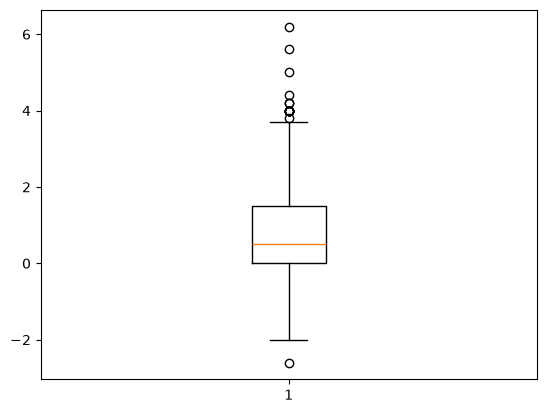

In [75]:
# finding outliers
plt.boxplot(data['oldpeak'].dropna())
plt.show()

In [76]:
data['oldpeak'].nunique()

53

In [77]:
# filling null values
median = data['oldpeak'].median()
data['oldpeak'] = data['oldpeak'].fillna(median)

In [78]:
data.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
thal        0
num         0
dtype: int64

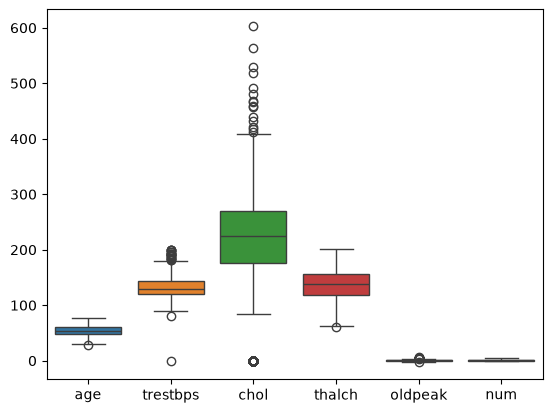

In [79]:
# finding outliers
sns.boxplot(data)
plt.show()

In [80]:
# handling outliers

num_cols = data.select_dtypes(include = np.number).columns

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR =Q3 - Q1
    print(col ,IQR)

    lower = Q1-1.5*IQR
    upper = Q3+1.5*IQR

    print('lower : ',lower)
    print('upper : ',upper)
    print('__________')

    data = data[(data[col]>=lower) & (data[col] <=upper)]
    data

age 12.25
lower :  29.375
upper :  78.375
__________
trestbps 24.0
lower :  84.0
upper :  180.0
__________
chol 93.0
lower :  37.5
upper :  409.5
__________
thalch 40.0
lower :  60.0
upper :  220.0
__________
oldpeak 1.5
lower :  -2.25
upper :  3.75
__________
num 1.0
lower :  -1.5
upper :  2.5
__________


In [81]:
# sns.boxplot(data)
# plt.show()

In [82]:
data.shape

(617, 13)

In [83]:
#Unique values

obj_cols = data.select_dtypes(include='object').columns

for col in obj_cols:
    print(col, ":", data[col].unique())


sex : <StringArray>
['Male', 'Female']
Length: 2, dtype: str
cp : <StringArray>
['typical angina', 'atypical angina', 'asymptomatic', 'non-anginal']
Length: 4, dtype: str
fbs : [True False 'FALSE' 'TRUE']
restecg : <StringArray>
['lv hypertrophy', 'normal', 'st-t abnormality']
Length: 3, dtype: str
exang : [False True 'FALSE' 'TURE']
slope : <StringArray>
['downsloping', 'flat', 'upsloping']
Length: 3, dtype: str
thal : <StringArray>
['fixed defect', 'normal', 'reversable defect']
Length: 3, dtype: str


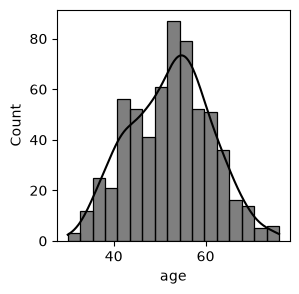

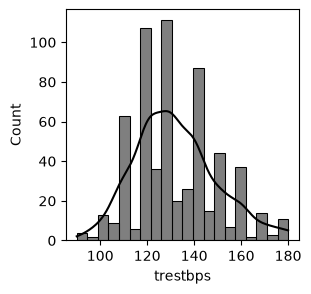

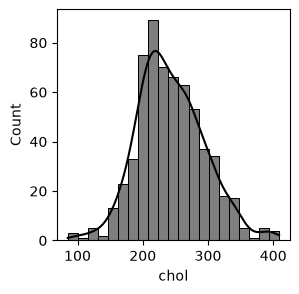

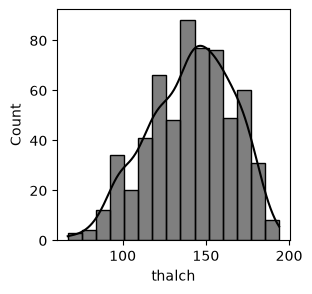

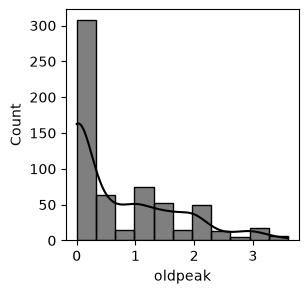

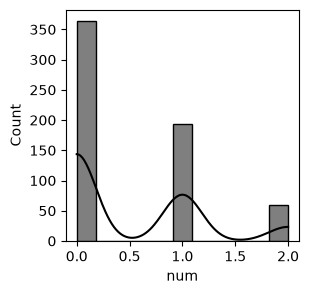

In [84]:
# hist plot
num_col = data.select_dtypes(include='number').columns
for col in num_col:
    plt.figure(figsize=(3,3))
    plt.xlabel(col)
    sns.histplot(data[col],kde=True, color='k')
    plt.show()


<Axes: >

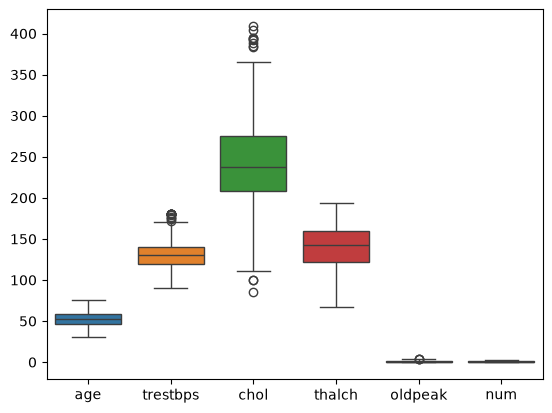

In [85]:
sns.boxplot(data)

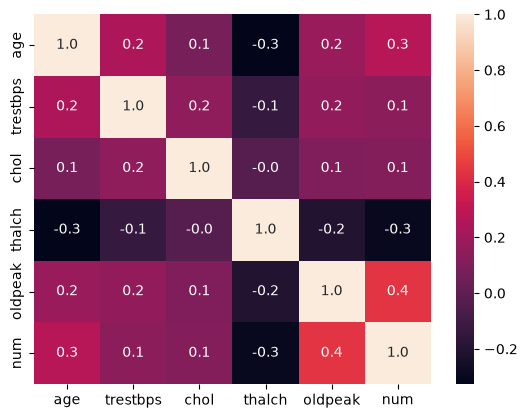

In [86]:
corr = data.select_dtypes(include=['int64', 'float']).corr()

sns.heatmap(corr , annot=True, fmt='.1f')
plt.show()

### 3. Feature Engineering:

In [87]:
# encoding
data['sex'] = data['sex'].map({'Male': 1, 'Female': 0})
data['fbs'] = data['fbs'].map({True: 1, False: 0})


In [88]:
data

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,1,typical angina,145,233,1.0,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,1,atypical angina,135,203,0.0,normal,132,False,0.0,flat,fixed defect,0
2,57,1,asymptomatic,140,192,0.0,normal,148,False,0.4,flat,fixed defect,0
3,52,1,typical angina,118,186,0.0,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,1,asymptomatic,110,201,0.0,normal,126,True,1.5,flat,fixed defect,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
762,72,1,asymptomatic,160,213,1.0,lv hypertrophy,130,False,1.5,upsloping,fixed defect,2
764,58,1,non-anginal,150,219,0.0,st-t abnormality,118,True,0.0,downsloping,fixed defect,2
765,58,1,non-anginal,150,219,0.0,st-t abnormality,118,True,0.0,downsloping,fixed defect,2
767,58,1,non-anginal,158,232,0.0,st-t abnormality,138,TURE,0.5,downsloping,normal,2


In [89]:
# encoding
data = pd.get_dummies(data, drop_first=True, dtype=int)


In [90]:
data

,age,sex,trestbps,chol,fbs,thalch,oldpeak,num,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,exang_True,exang_FALSE,exang_TURE,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63,1,145,233,1.0,150,2.3,0,0,0,1,0,0,0,0,0,0,0,0,0
1,41,1,135,203,0.0,132,0.0,0,1,0,0,1,0,0,0,0,1,0,0,0
2,57,1,140,192,0.0,148,0.4,0,0,0,0,1,0,0,0,0,1,0,0,0
3,52,1,118,186,0.0,190,0.0,0,0,0,1,0,0,0,0,0,1,0,0,0
4,57,1,110,201,0.0,126,1.5,0,0,0,0,1,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
762,72,1,160,213,1.0,130,1.5,2,0,0,0,0,0,0,0,0,0,1,0,0
764,58,1,150,219,0.0,118,0.0,2,0,1,0,0,1,1,0,0,0,0,0,0
765,58,1,150,219,0.0,118,0.0,2,0,1,0,0,1,1,0,0,0,0,0,0
767,58,1,158,232,0.0,138,0.5,2,0,1,0,0,1,0,0,1,0,0,1,0


### 4. Decision Tree Classification:

In [91]:
# split data
X = data.drop("num", axis=1)
y = data["num"]


In [92]:
from sklearn.model_selection import train_test_split

In [93]:
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42)
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((493, 19), (124, 19), (493,), (124,))

In [94]:
from sklearn.tree import DecisionTreeClassifier

In [95]:
# build model
model = DecisionTreeClassifier(max_depth=3)
model.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [96]:
# evaluation of model

from sklearn.metrics import confusion_matrix, classification_report

In [97]:
y_pred = model.predict(X_train)

In [98]:
cm = confusion_matrix(y_train, y_pred)
cm
# plt.figure(figsize=(3,3))
# sns.heatmap(cm, annot=True, fmt='.2f')

array([[250,  36,   2],
       [ 60,  98,   5],
       [ 16,  16,  10]])

In [99]:
print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           0       0.77      0.87      0.81       288
           1       0.65      0.60      0.63       163
           2       0.59      0.24      0.34        42

    accuracy                           0.73       493
   macro avg       0.67      0.57      0.59       493
weighted avg       0.71      0.73      0.71       493



In [100]:
y_pred = model.predict(X_test)

In [101]:
cm = confusion_matrix(y_test,y_pred)
cm
# plt.figure(figsize=(3,3))
# sns.heatmap(cm, annot=True, fmt='.2f')

array([[66, 10,  0],
       [15, 13,  3],
       [ 8,  8,  1]])

In [102]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.74      0.87      0.80        76
           1       0.42      0.42      0.42        31
           2       0.25      0.06      0.10        17

    accuracy                           0.65       124
   macro avg       0.47      0.45      0.44       124
weighted avg       0.59      0.65      0.61       124



In [103]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)

roc_auc_score(y_test, y_prob, multi_class='ovr')


0.7246915294368486

### 5. Hyperparameter Tuning:

In [112]:
# hyper parameter tunning

from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2,3,4,5,6,7,8,9,10,15, None],
    'min_samples_split': [2,3,4, 5,6,7,8,9, 10],
    'min_samples_leaf': [1,2,3,4],
    'criterion': ['gini', 'entropy']
}


In [113]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...r(max_depth=3)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",Tru

In [114]:
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)


Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Score: 0.6958152958152959


### 6. Model Evaluation and Analysis:

In [115]:
best_model = grid_search.best_estimator_
best_model

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [116]:
y_pred = model.predict(X_test)

In [117]:
cm = confusion_matrix(y_test,y_pred)
cm
# plt.figure(figsize=(3,3))
# sns.heatmap(cm, annot=True, fmt='.2f')

array([[66, 10,  0],
       [15, 13,  3],
       [ 8,  8,  1]])

In [118]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.74      0.87      0.80        76
           1       0.42      0.42      0.42        31
           2       0.25      0.06      0.10        17

    accuracy                           0.65       124
   macro avg       0.47      0.45      0.44       124
weighted avg       0.59      0.65      0.61       124



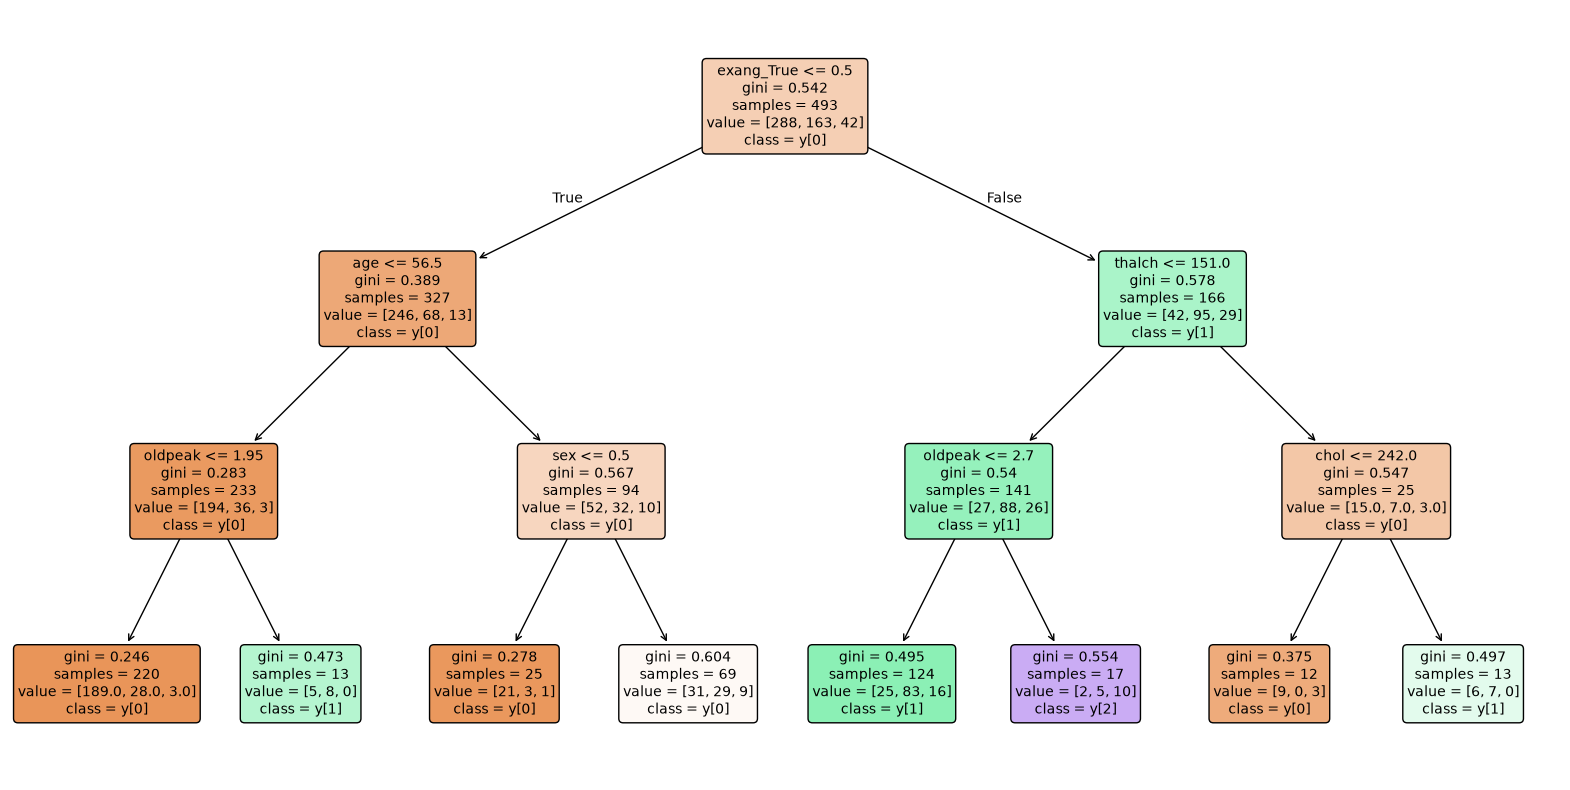

In [119]:
# ploting the tree

from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(model,
          feature_names=X.columns,
          class_names=True,   # or provide class labels list
          filled=True,
          rounded=True)

plt.show()


### interview questions